In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 2:
        dirs[:] = []
        continue
    print(root)
    for f in files[:10]:
        print("  ", f)

/kaggle/input
/kaggle/input/competitions
/kaggle/input/competitions/rsna-knee-abnormality-detection
   test_series.csv
   train_series.csv
   sample_submission.csv
   train.csv
   test.csv


In [2]:

import os
import sys
import pandas as pd

DATA = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

print("=== ENVIRONMENT ===")
print("Python:", sys.version)

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is not installed.")

print("\n=== DATA FILES ===")
for name in os.listdir(DATA):
    path = os.path.join(DATA, name)
    size = os.path.getsize(path) if os.path.isfile(path) else None
    print(name, f"({size:,} bytes)" if size is not None else "(directory)")

print("\n=== TRAINING DATA CHECK ===")
train = pd.read_csv(os.path.join(DATA, "train.csv"))
series = pd.read_csv(os.path.join(DATA, "train_series.csv"))

print("train.csv:", train.shape)
print("train_series.csv:", series.shape)
print("Columns in train_series.csv:", series.columns.tolist())
print("Studies:", train["StudyInstanceUID"].nunique())
print("Series rows:", len(series))


=== ENVIRONMENT ===
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cpu
CUDA available: False

=== DATA FILES ===
test_series.csv (2,213 bytes)
train_series.csv (3,458,834 bytes)
sample_submission.csv (470 bytes)
test_series (directory)
train_series (directory)
train.csv (5,690,007 bytes)
test.csv (212 bytes)

=== TRAINING DATA CHECK ===
train.csv: (4407, 14)
train_series.csv: (24371, 5)
Columns in train_series.csv: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']
Studies: 4407
Series rows: 24371


In [2]:
from pathlib import Path

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")

for folder in ["train_series", "test_series"]:
    path = DATA / folder
    print(f"\n{folder}: exists={path.exists()}")

    if path.exists():
        files = list(path.iterdir())
        print("Number of top-level entries:", len(files))
        print("First five entries:", [p.name for p in files[:5]])


train_series: exists=True
Number of top-level entries: 4407
First five entries: ['1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839', '1.2.826.0.1.3680043.8.498.11425683153901568541658945026861110110', '1.2.826.0.1.3680043.8.498.68524920268469128133836299591793117756', '1.2.826.0.1.3680043.8.498.65222333228514862688331581862087607325', '1.2.826.0.1.3680043.8.498.27653320597564308144389724321115208375']

test_series: exists=True
Number of top-level entries: 3
First five entries: ['1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776', '1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402', '1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191']


In [3]:

from pathlib import Path

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
study = next((DATA / "train_series").iterdir())

print("Study:", study.name)

for series in list(study.iterdir())[:5]:
    print(f"\nSeries/path: {series.name}")
    if series.is_dir():
        files = list(series.iterdir())
        print("File count:", len(files))
        print("First 5 files:", [f.name for f in files[:5]])
    else:
        print("File:", series.name)


Study: 1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839

Series/path: 1.2.826.0.1.3680043.8.498.28798546215369442215420222435134673142
File count: 186
First 5 files: ['1.2.826.0.1.3680043.8.498.12486678153168904030743072482872142065.dcm', '1.2.826.0.1.3680043.8.498.86700687663805155070115680323395754377.dcm', '1.2.826.0.1.3680043.8.498.40362622123295797247686695535473040667.dcm', '1.2.826.0.1.3680043.8.498.22606964411658655718893941683908738828.dcm', '1.2.826.0.1.3680043.8.498.47226698003996911677858077867948563321.dcm']

Series/path: 1.2.826.0.1.3680043.8.498.77574746339062590058612008891367008722
File count: 25
First 5 files: ['1.2.826.0.1.3680043.8.498.56284095178133202956135847560312414284.dcm', '1.2.826.0.1.3680043.8.498.11004430134468021678053141135177865912.dcm', '1.2.826.0.1.3680043.8.498.10506135797312946201979725248949720258.dcm', '1.2.826.0.1.3680043.8.498.12347541309741808900959811581790707183.dcm', '1.2.826.0.1.3680043.8.498.11097134176995757742095579196643

In [4]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [5]:

from pathlib import Path
import pandas as pd
import importlib.util

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")

# 1. Check required libraries
for package in ["pydicom", "numpy", "sklearn", "torchvision"]:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package) else "NOT INSTALLED")

# 2. Inspect label distribution
train = pd.read_csv(DATA / "train.csv")
series = pd.read_csv(DATA / "train_series.csv")

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

labelled = train[train[targets].notna().any(axis=1)].copy()
print("\nLabelled studies:", len(labelled))
print("\nPositive labels:")
print(labelled[targets].sum().sort_values(ascending=False).to_string())

# 3. Inspect series associated with labelled studies
labelled_ids = set(labelled["StudyInstanceUID"])
labelled_series = series[series["StudyInstanceUID"].isin(labelled_ids)]

print("\nSeries belonging to labelled studies:", len(labelled_series))
print("\nAnatomical plane counts:")
print(labelled_series["Anatomical_Plane"].value_counts(dropna=False).to_string())

print("\nFluid-sensitive counts:")
print(labelled_series["Fluid_Sensitive"].value_counts(dropna=False).to_string())

print("\nExample series metadata:")
print(labelled_series.head(10).to_string(index=False))

# 4. Find a DICOM from a labelled study
import pydicom

sample_path = None
for study_id in labelled_ids:
    study_dir = DATA / "train_series" / study_id
    if not study_dir.exists():
        continue
    for series_dir in study_dir.iterdir():
        if not series_dir.is_dir():
            continue
        dicoms = list(series_dir.glob("*.dcm"))
        if dicoms:
            sample_path = dicoms[0]
            break
    if sample_path:
        break

if sample_path is None:
    print("\nNo DICOM found in the labelled studies.")
else:
    ds = pydicom.dcmread(str(sample_path))
    print("\n=== SAMPLE DICOM ===")
    print("Path:", sample_path)
    print("Rows x columns:", getattr(ds, "Rows", None),
          "x", getattr(ds, "Columns", None))
    print("Modality:", getattr(ds, "Modality", None))
    print("Series description:", getattr(ds, "SeriesDescription", None))
    print("Instance number:", getattr(ds, "InstanceNumber", None))
    print("Pixel data present:", hasattr(ds, "PixelData"))
    if hasattr(ds, "pixel_array"):
        image = ds.pixel_array
        print("Decoded pixel shape:", image.shape)
        print("Pixel dtype:", image.dtype)


pydicom: available
numpy: available
sklearn: available
torchvision: available

Labelled studies: 58

Positive labels:
Effusion            35.0
Synovitis           27.0
Medial Meniscus     26.0
ACL                 24.0
Lateral Meniscus    23.0
PF OA               21.0
Contusion           19.0
Fracture            18.0
Medial OA           15.0
Baker's             12.0
Lateral OA          11.0
MCL                  9.0

Series belonging to labelled studies: 336

Anatomical plane counts:
Anatomical_Plane
Sagittal    136
Coronal     119
Axial        81

Fluid-sensitive counts:
Fluid_Sensitive
1    192
0    144

Example series metadata:
                                                StudyInstanceUID                                                SeriesInstanceUID  Fluid_Sensitive  Fat_Suppression Anatomical_Plane
1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149 1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282                0                0         Sagittal
1

In [6]:

import pandas as pd
from sklearn.model_selection import train_test_split

DATA = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

df = pd.read_csv(f"{DATA}/train.csv")

targets = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

labelled = df.loc[df[targets].notna().all(axis=1)].copy()
labelled[targets] = labelled[targets].astype(int)

print("Labelled studies:", len(labelled))
print("Unique studies:", labelled["StudyInstanceUID"].nunique())
print("Duplicate study IDs:", labelled["StudyInstanceUID"].duplicated().sum())

# Inspect whether an ordinary single-target stratification is viable.
print("\nPositive counts:")
print(labelled[targets].sum().sort_values().to_string())

train_ids, val_ids = train_test_split(
    labelled["StudyInstanceUID"].tolist(),
    test_size=0.25,
    random_state=42,
    stratify=labelled["ACL"]
)

train_labels = labelled[labelled["StudyInstanceUID"].isin(train_ids)]
val_labels = labelled[labelled["StudyInstanceUID"].isin(val_ids)]

print("\nSplit sizes:")
print("Training:", len(train_labels))
print("Validation:", len(val_labels))

print("\nPositive counts by split:")
print("Training:")
print(train_labels[targets].sum().to_string())
print("\nValidation:")
print(val_labels[targets].sum().to_string())

assert set(train_ids).isdisjoint(set(val_ids))
assert len(train_ids) + len(val_ids) == len(labelled)
print("\nStudy-level split checks passed.")


Labelled studies: 58
Unique studies: 58
Duplicate study IDs: 0

Positive counts:
MCL                  9
Lateral OA          11
Baker's             12
Medial OA           15
Fracture            18
Contusion           19
PF OA               21
Lateral Meniscus    23
ACL                 24
Medial Meniscus     26
Synovitis           27
Effusion            35

Split sizes:
Training: 43
Validation: 15

Positive counts by split:
Training:
ACL                 18
MCL                  6
Medial Meniscus     19
Lateral Meniscus    17
Medial OA           13
Lateral OA           8
PF OA               18
Effusion            25
Synovitis           21
Baker's              9
Contusion           13
Fracture             8

Validation:
ACL                  6
MCL                  3
Medial Meniscus      7
Lateral Meniscus     6
Medial OA            2
Lateral OA           3
PF OA                3
Effusion            10
Synovitis            6
Baker's              3
Contusion            6
Fracture            10

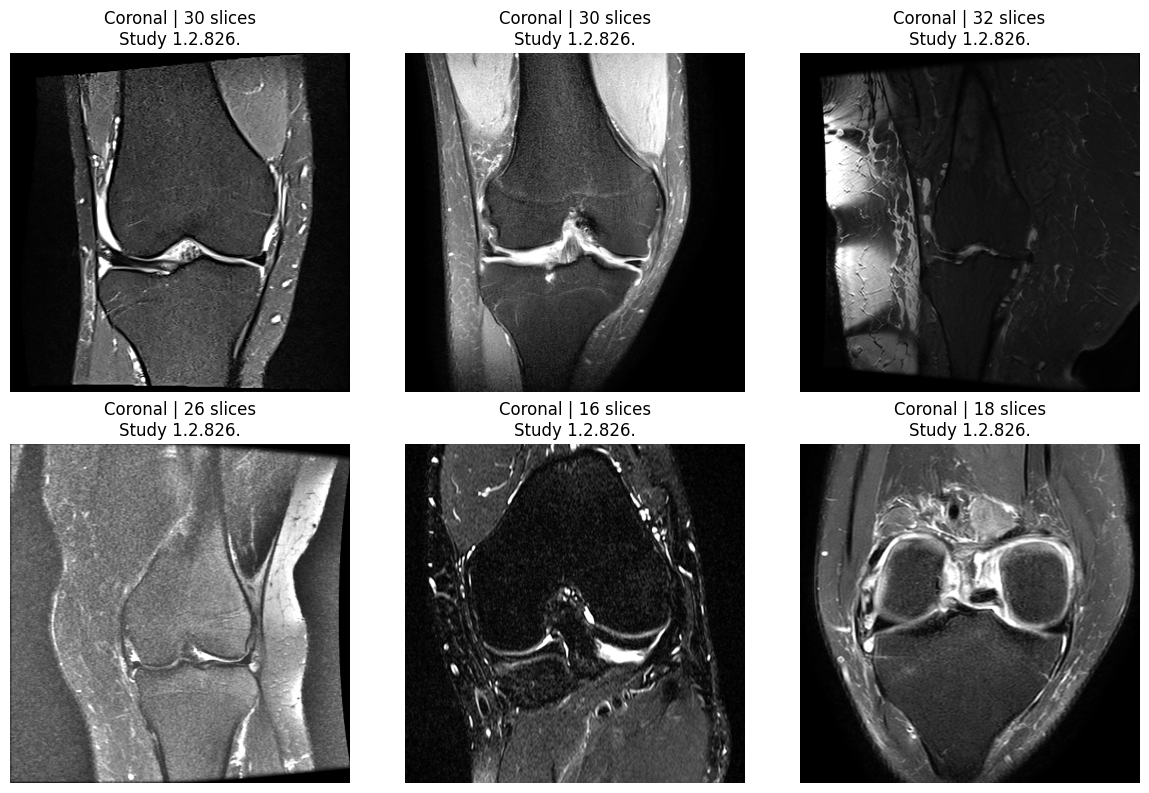

Training studies available in metadata: 43
Selected studies: 6
MRI slices successfully displayed: 6
Training IDs used: 43


In [7]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
TRAIN_DIR = DATA / "train_series"

# Reuse the training IDs from our verified study-level split.
series_df = pd.read_csv(DATA / "train_series.csv")
train_series = series_df[
    series_df["StudyInstanceUID"].isin(train_ids)
].copy()

# Prefer fluid-sensitive sagittal/coronal series for this first inspection.
preferred = train_series[
    (train_series["Fluid_Sensitive"] == 1) &
    (train_series["Anatomical_Plane"].str.lower().isin(["sagittal", "coronal"]))
].copy()

# Select up to six distinct training studies.
selected = (
    preferred.sort_values(["StudyInstanceUID", "Anatomical_Plane"])
    .drop_duplicates("StudyInstanceUID")
    .head(6)
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
shown = 0

for ax, (_, row) in zip(axes.flat, selected.iterrows()):
    study_id = row["StudyInstanceUID"]
    series_id = row["SeriesInstanceUID"]
    folder = TRAIN_DIR / str(study_id) / str(series_id)

    files = list(folder.glob("*.dcm"))
    if not files:
        ax.set_title(f"{study_id[:8]}: no DICOM files")
        ax.axis("off")
        continue

    # Sort by DICOM InstanceNumber where available.
    slices = []
    for path in files:
        try:
            ds = pydicom.dcmread(path)
            if hasattr(ds, "PixelData"):
                instance = int(getattr(ds, "InstanceNumber", 0))
                slices.append((instance, ds))
        except Exception:
            continue

    if not slices:
        ax.set_title(f"{study_id[:8]}: decoding failed")
        ax.axis("off")
        continue

    slices.sort(key=lambda item: item[0])
    ds = slices[len(slices) // 2][1]
    pixels = ds.pixel_array.astype(np.float32)

    # Robust display scaling; this is for visual inspection, not yet
    # the final model's preprocessing.
    lo, hi = np.percentile(pixels, [1, 99])
    if hi > lo:
        pixels = np.clip((pixels - lo) / (hi - lo), 0, 1)

    ax.imshow(pixels, cmap="gray")
    ax.set_title(
        f"{row['Anatomical_Plane']} | {len(slices)} slices\n"
        f"Study {study_id[:8]}"
    )
    ax.axis("off")
    shown += 1

plt.tight_layout()
plt.show()

print(f"Training studies available in metadata: "
      f"{train_series['StudyInstanceUID'].nunique()}")
print(f"Selected studies: {len(selected)}")
print(f"MRI slices successfully displayed: {shown}")
print("Training IDs used:", len(train_ids))


Device: cuda
GPU: Tesla T4
Usable training studies: 43
Usable validation studies: 15
Epoch 1/5 — training BCE loss: 0.6738
Epoch 2/5 — training BCE loss: 0.6395
Epoch 3/5 — training BCE loss: 0.6127
Epoch 4/5 — training BCE loss: 0.5928
Epoch 5/5 — training BCE loss: 0.5943

Per-target validation ROC-AUC:
ACL                  0.315
MCL                  0.389
Medial Meniscus      0.464
Lateral Meniscus     0.704
Medial OA            0.346
Lateral OA           0.556
PF OA                0.583
Effusion             0.820
Synovitis            0.296
Baker's              0.722
Contusion            0.426
Fracture             0.400

Macro ROC-AUC over evaluable targets: 0.5018
Evaluable targets: 12/12
NOTE: tiny validation set; this score is highly uncertain.


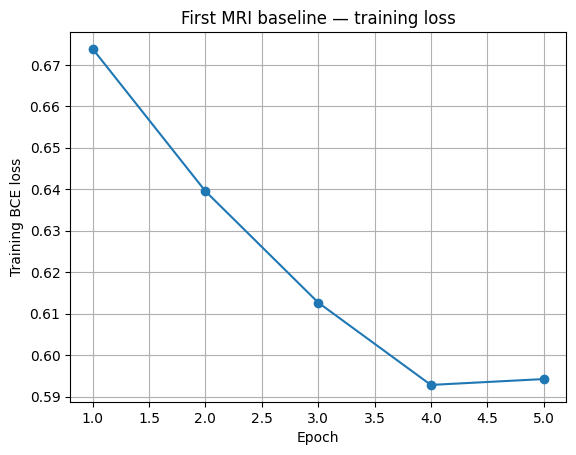

In [8]:

from pathlib import Path
import random
import numpy as np
import pandas as pd
import pydicom
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
TRAIN_DIR = DATA / "train_series"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

labels_df = pd.read_csv(DATA / "train.csv")
labels_df = labels_df.dropna(subset=TARGETS).copy()
labels_df[TARGETS] = labels_df[TARGETS].astype(np.float32)
labels_by_id = labels_df.set_index("StudyInstanceUID")

series_df = pd.read_csv(DATA / "train_series.csv")
series_df["Anatomical_Plane"] = (
    series_df["Anatomical_Plane"].astype(str).str.lower()
)

# One fluid-sensitive sagittal/coronal series per study.
eligible = series_df[
    (series_df["Fluid_Sensitive"] == 1) &
    (series_df["Anatomical_Plane"].isin(["sagittal", "coronal"]))
].copy()

def load_study_slices(study_id):
    candidates = eligible[eligible["StudyInstanceUID"] == study_id].copy()
    if candidates.empty:
        return []

    # Prefer sagittal; coronal is the fallback.
    candidates["plane_rank"] = (
        candidates["Anatomical_Plane"] != "sagittal"
    ).astype(int)
    candidates = candidates.sort_values("plane_rank")

    for _, row in candidates.iterrows():
        folder = TRAIN_DIR / str(study_id) / str(row["SeriesInstanceUID"])
        paths = list(folder.glob("*.dcm"))
        decoded = []

        for path in paths:
            try:
                ds = pydicom.dcmread(path)
                if hasattr(ds, "PixelData"):
                    decoded.append((
                        int(getattr(ds, "InstanceNumber", 0)),
                        path
                    ))
            except Exception:
                continue

        decoded.sort(key=lambda x: x[0])
        if len(decoded) < 3:
            continue

        # Three evenly spaced slices; avoid repeatedly sampling the centre.
        indices = np.linspace(0, len(decoded) - 1, 3).round().astype(int)
        images = []

        for idx in indices:
            try:
                ds = pydicom.dcmread(decoded[idx][1])
                arr = ds.pixel_array.astype(np.float32)
                lo, hi = np.percentile(arr, [1, 99])
                if hi > lo:
                    arr = np.clip((arr - lo) / (hi - lo), 0, 1)
                else:
                    arr = np.zeros_like(arr)

                # Simple nearest-neighbour resize without extra dependencies.
                ys = np.linspace(0, arr.shape[0] - 1, 96).astype(int)
                xs = np.linspace(0, arr.shape[1] - 1, 96).astype(int)
                arr = arr[np.ix_(ys, xs)]
                images.append(np.repeat(arr[None, :, :], 3, axis=0))
            except Exception:
                images = []
                break

        if len(images) == 3:
            return images

    return []

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Cache image decoding so epochs don't repeatedly read DICOM files.
study_images = {}
for sid in labels_df["StudyInstanceUID"]:
    images = load_study_slices(sid)
    if len(images) == 3:
        study_images[sid] = np.stack(images)

usable_ids = [sid for sid in study_images if sid in labels_by_id.index]
train_usable = [sid for sid in train_ids if sid in usable_ids]
val_usable = [sid for sid in val_ids if sid in usable_ids]

print("Usable training studies:", len(train_usable))
print("Usable validation studies:", len(val_usable))

if len(train_usable) < 20 or len(val_usable) < 5:
    raise RuntimeError(
        "Too few usable studies. Stop here and inspect the series selection."
    )

class SliceDataset(Dataset):
    def __init__(self, ids):
        self.samples = [(sid, i) for sid in ids for i in range(3)]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        sid, slice_idx = self.samples[index]
        x = torch.tensor(study_images[sid][slice_idx], dtype=torch.float32)
        y = torch.tensor(
            labels_by_id.loc[sid, TARGETS].to_numpy(dtype=np.float32)
        )
        return x, y

class SmallCNN(nn.Module):
    def __init__(self, n_targets=12):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 96, 3, padding=1), nn.BatchNorm2d(96),
            nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(96, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, n_targets)
        )

    def forward(self, x):
        return self.head(self.features(x))

train_loader = DataLoader(
    SliceDataset(train_usable), batch_size=12, shuffle=True,
    num_workers=2, pin_memory=(DEVICE.type == "cuda")
)

model = SmallCNN(len(TARGETS)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
criterion = nn.BCEWithLogitsLoss()

history = []
for epoch in range(5):
    model.train()
    losses = []

    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    mean_loss = float(np.mean(losses))
    history.append(mean_loss)
    print(f"Epoch {epoch + 1}/5 — training BCE loss: {mean_loss:.4f}")

# Study-level validation: average the three slice probabilities.
model.eval()
val_true, val_prob = [], []

with torch.no_grad():
    for sid in val_usable:
        x = torch.tensor(study_images[sid], dtype=torch.float32).to(DEVICE)
        probs = torch.sigmoid(model(x)).cpu().numpy()
        val_prob.append(probs.mean(axis=0))
        val_true.append(labels_by_id.loc[sid, TARGETS].to_numpy(dtype=int))

val_true = np.asarray(val_true)
val_prob = np.asarray(val_prob)

auc_by_target = {}
for j, target in enumerate(TARGETS):
    if len(np.unique(val_true[:, j])) == 2:
        auc_by_target[target] = roc_auc_score(val_true[:, j], val_prob[:, j])
    else:
        auc_by_target[target] = np.nan

valid_aucs = [v for v in auc_by_target.values() if np.isfinite(v)]
macro_auc = float(np.mean(valid_aucs)) if valid_aucs else np.nan

print("\nPer-target validation ROC-AUC:")
for target, score in auc_by_target.items():
    print(f"{target:20s}", "undefined" if not np.isfinite(score) else f"{score:.3f}")

print(f"\nMacro ROC-AUC over evaluable targets: {macro_auc:.4f}")
print(f"Evaluable targets: {len(valid_aucs)}/{len(TARGETS)}")
print("NOTE: tiny validation set; this score is highly uncertain.")

plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training BCE loss")
plt.title("First MRI baseline — training loss")
plt.grid(True)
plt.show()


In [9]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

model.eval()

def predict_studies(study_ids):
    predictions = []
    truths = []

    with torch.no_grad():
        for sid in study_ids:
            x = torch.tensor(
                study_images[sid], dtype=torch.float32
            ).to(DEVICE)

            # Three slice-level predictions, averaged per study.
            probs = torch.sigmoid(model(x)).cpu().numpy()
            predictions.append(probs.mean(axis=0))
            truths.append(
                labels_by_id.loc[sid, TARGETS].to_numpy(dtype=int)
            )

    return np.asarray(truths), np.asarray(predictions)

train_y, train_p = predict_studies(train_usable)
val_y, val_p = predict_studies(val_usable)

rows = []
for j, target in enumerate(TARGETS):
    train_auc = (
        roc_auc_score(train_y[:, j], train_p[:, j])
        if len(np.unique(train_y[:, j])) == 2 else np.nan
    )
    val_auc = (
        roc_auc_score(val_y[:, j], val_p[:, j])
        if len(np.unique(val_y[:, j])) == 2 else np.nan
    )

    rows.append({
        "Target": target,
        "Train AUC": train_auc,
        "Validation AUC": val_auc,
        "Train score SD": np.std(train_p[:, j]),
        "Validation score SD": np.std(val_p[:, j]),
        "Train positive rate": train_y[:, j].mean(),
        "Validation positive rate": val_y[:, j].mean(),
    })

diagnostics = pd.DataFrame(rows)
display(diagnostics.round(3))

print("Mean training prediction SD:", round(float(train_p.std(axis=0).mean()), 4))
print("Mean validation prediction SD:", round(float(val_p.std(axis=0).mean()), 4))
print("Mean train AUC:", round(float(
    diagnostics["Train AUC"].mean()
), 4))
print("Mean validation AUC:", round(float(
    diagnostics["Validation AUC"].mean()
), 4))


,Target,Train AUC,Validation AUC,Train score SD,Validation score SD,Train positive rate,Validation positive rate
0,ACL,0.671,0.315,0.047,0.027,0.419,0.400
1,MCL,0.716,0.389,0.015,0.015,0.140,0.200
2,Medial Meniscus,0.713,0.464,0.041,0.039,0.442,0.467
3,Lateral Meniscus,0.636,0.704,0.037,0.024,0.395,0.400
4,Medial OA,0.785,0.346,0.034,0.019,0.302,0.133
5,Lateral OA,0.639,0.556,0.018,0.019,0.186,0.200
6,PF OA,0.598,0.583,0.026,0.021,0.419,0.200
7,Effusion,0.667,0.820,0.060,0.044,0.581,0.667
8,Synovitis,0.721,0.296,0.020,0.015,0.488,0.400
9,Baker's,0.703,0.722,0.019,0.017,0.209,0.200


Mean training prediction SD: 0.0319
Mean validation prediction SD: 0.0268
Mean train AUC: 0.6782
Mean validation AUC: 0.5018


In [11]:

import copy
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score

torch.manual_seed(42)
np.random.seed(42)

class StudyDataset(Dataset):
    def __init__(self, ids):
        self.ids = list(ids)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        sid = self.ids[idx]

        # Use one grayscale channel from each of the 3 sampled slices.
        # Shape: [3 slices, 96, 96], one sample per study.
        x = torch.tensor(
            study_images[sid][:, 0, :, :],
            dtype=torch.float32
        )

        y = torch.tensor(
            labels_by_id.loc[sid, TARGETS].to_numpy(dtype=np.float32)
        )
        return x, y

class StudyCNN(nn.Module):
    def __init__(self, n_targets=12):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 24, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(24, n_targets)
        )

    def forward(self, x):
        return self.net(x)

train_loader = DataLoader(
    StudyDataset(train_usable),
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

model_v2 = StudyCNN(len(TARGETS)).to(DEVICE)
optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(), lr=5e-4, weight_decay=0.02
)
criterion_v2 = nn.BCEWithLogitsLoss()

best_loss = float("inf")
best_state = None
patience = 5
stale_epochs = 0
history_v2 = []

# Early stopping uses training loss only; validation is not used to select epochs.
for epoch in range(30):
    model_v2.train()
    losses = []

    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer_v2.zero_grad()
        logits = model_v2(xb)
        loss = criterion_v2(logits, yb)
        loss.backward()
        optimizer_v2.step()
        losses.append(loss.item())

    epoch_loss = float(np.mean(losses))
    history_v2.append(epoch_loss)
    print(f"Epoch {epoch + 1:02d} — study-level BCE: {epoch_loss:.4f}")

    if epoch_loss < best_loss - 1e-4:
        best_loss = epoch_loss
        best_state = copy.deepcopy(model_v2.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1

    if stale_epochs >= patience:
        print("Stopped early based on training loss.")
        break

model_v2.load_state_dict(best_state)
model_v2.eval()

val_true_v2, val_prob_v2 = [], []
with torch.no_grad():
    for sid in val_usable:
        x = torch.tensor(
            study_images[sid][:, 0, :, :],
            dtype=torch.float32
        ).unsqueeze(0).to(DEVICE)

        prob = torch.sigmoid(model_v2(x)).cpu().numpy()[0]
        val_prob_v2.append(prob)
        val_true_v2.append(
            labels_by_id.loc[sid, TARGETS].to_numpy(dtype=int)
        )

val_true_v2 = np.asarray(val_true_v2)
val_prob_v2 = np.asarray(val_prob_v2)

aucs_v2 = {}
for j, target in enumerate(TARGETS):
    if len(np.unique(val_true_v2[:, j])) == 2:
        aucs_v2[target] = roc_auc_score(
            val_true_v2[:, j], val_prob_v2[:, j]
        )
    else:
        aucs_v2[target] = np.nan

valid_v2 = [v for v in aucs_v2.values() if np.isfinite(v)]
macro_v2 = float(np.mean(valid_v2)) if valid_v2 else np.nan

print("\nStudy-level CNN results:")
for target, score in aucs_v2.items():
    print(f"{target:20s}",
          "undefined" if not np.isfinite(score) else f"{score:.3f}")

print(f"\nMacro validation ROC-AUC: {macro_v2:.4f}")
print(f"Evaluable targets: {len(valid_v2)}/{len(TARGETS)}")
print("Prediction SD:", round(float(val_prob_v2.std(axis=0).mean()), 4))
print("First model macro AUC: 0.5018")


Epoch 01 — study-level BCE: 0.7037
Epoch 02 — study-level BCE: 0.7022
Epoch 03 — study-level BCE: 0.7002
Epoch 04 — study-level BCE: 0.6978
Epoch 05 — study-level BCE: 0.6951
Epoch 06 — study-level BCE: 0.6902
Epoch 07 — study-level BCE: 0.6860
Epoch 08 — study-level BCE: 0.6840
Epoch 09 — study-level BCE: 0.6762
Epoch 10 — study-level BCE: 0.6703
Epoch 11 — study-level BCE: 0.6780
Epoch 12 — study-level BCE: 0.6658
Epoch 13 — study-level BCE: 0.6669
Epoch 14 — study-level BCE: 0.6575
Epoch 15 — study-level BCE: 0.6532
Epoch 16 — study-level BCE: 0.6388
Epoch 17 — study-level BCE: 0.6443
Epoch 18 — study-level BCE: 0.6461
Epoch 19 — study-level BCE: 0.6344
Epoch 20 — study-level BCE: 0.6477
Epoch 21 — study-level BCE: 0.6149
Epoch 22 — study-level BCE: 0.6473
Epoch 23 — study-level BCE: 0.6412
Epoch 24 — study-level BCE: 0.6439
Epoch 25 — study-level BCE: 0.6365
Epoch 26 — study-level BCE: 0.6218
Stopped early based on training loss.

Study-level CNN results:
ACL                  0.333

In [12]:

import numpy as np
import pandas as pd

series_df = pd.read_csv(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv"
)

series_df["Anatomical_Plane"] = (
    series_df["Anatomical_Plane"].astype(str).str.lower()
)

eligible = series_df[
    (series_df["Fluid_Sensitive"] == 1) &
    (series_df["Anatomical_Plane"].isin(["sagittal", "coronal"]))
].copy()

eligible["plane_rank"] = (
    eligible["Anatomical_Plane"] != "sagittal"
).astype(int)

eligible = eligible.sort_values(
    ["StudyInstanceUID", "plane_rank"]
)

chosen = eligible.drop_duplicates("StudyInstanceUID")

print("Labelled studies:", len(labels_df))
print("Studies with a preferred series:", chosen["StudyInstanceUID"].nunique())
print("\nChosen series plane counts:")
print(chosen["Anatomical_Plane"].value_counts())

# Count actual DICOM files in each chosen series.
from pathlib import Path

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
TRAIN_DIR = DATA / "train_series"

counts = []
for _, row in chosen[
    chosen["StudyInstanceUID"].isin(labels_df["StudyInstanceUID"])
].iterrows():
    folder = (
        TRAIN_DIR
        / str(row["StudyInstanceUID"])
        / str(row["SeriesInstanceUID"])
    )
    n = len(list(folder.glob("*.dcm")))
    counts.append({
        "StudyInstanceUID": row["StudyInstanceUID"],
        "Plane": row["Anatomical_Plane"],
        "Slices": n
    })

count_df = pd.DataFrame(counts)
print("\nSlices per selected series:")
print(count_df["Slices"].describe(percentiles=[.25, .5, .75, .9]))
print("\nTotal selected-series slices:", int(count_df["Slices"].sum()))
print("Slices sampled by our current pipeline:", 3 * len(study_images))


Labelled studies: 58
Studies with a preferred series: 4407

Chosen series plane counts:
Anatomical_Plane
sagittal    4150
coronal      257
Name: count, dtype: int64

Slices per selected series:
count     58.000000
mean      33.603448
std       38.823460
min       15.000000
25%       24.000000
50%       29.000000
75%       33.750000
90%       36.000000
max      320.000000
Name: Slices, dtype: float64

Total selected-series slices: 1949
Slices sampled by our current pipeline: 174


In [14]:

import numpy as np
import pandas as pd
from pathlib import Path
import pydicom

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
TRAIN_DIR = DATA / "train_series"

N_SLICES = 9
IMG_SIZE = 96

series_df = pd.read_csv(DATA / "train_series.csv")
series_df["Anatomical_Plane"] = (
    series_df["Anatomical_Plane"].astype(str).str.lower()
)

eligible = series_df[
    (series_df["Fluid_Sensitive"] == 1) &
    (series_df["Anatomical_Plane"].isin(["sagittal", "coronal"]))
].copy()

eligible["plane_rank"] = (
    eligible["Anatomical_Plane"] != "sagittal"
).astype(int)

eligible = eligible.sort_values(
    ["StudyInstanceUID", "plane_rank"]
)
chosen = eligible.drop_duplicates("StudyInstanceUID").set_index(
    "StudyInstanceUID"
)

def decode_nine_slices(study_id):
    if study_id not in chosen.index:
        return None

    row = chosen.loc[study_id]
    folder = (
        TRAIN_DIR / str(study_id) / str(row["SeriesInstanceUID"])
    )

    paths = list(folder.glob("*.dcm"))
    decoded = []

    for path in paths:
        try:
            ds = pydicom.dcmread(path)
            if hasattr(ds, "PixelData"):
                decoded.append((
                    int(getattr(ds, "InstanceNumber", 0)), path
                ))
        except Exception:
            continue

    decoded.sort(key=lambda x: x[0])

    if len(decoded) < N_SLICES:
        return None

    indices = np.linspace(
        0, len(decoded) - 1, N_SLICES
    ).round().astype(int)

    images = []

    for idx in indices:
        try:
            ds = pydicom.dcmread(decoded[idx][1])
            arr = ds.pixel_array.astype(np.float32)

            # Robust per-slice display scaling.
            lo, hi = np.percentile(arr, [1, 99])
            if hi > lo:
                arr = np.clip((arr - lo) / (hi - lo), 0, 1)
            else:
                arr = np.zeros_like(arr)

            ys = np.linspace(0, arr.shape[0] - 1, IMG_SIZE).astype(int)
            xs = np.linspace(0, arr.shape[1] - 1, IMG_SIZE).astype(int)
            arr = arr[np.ix_(ys, xs)]
            images.append(arr)
        except Exception:
            return None

    if len(images) != N_SLICES:
        return None

    return np.stack(images).astype(np.float32)  # [9, 96, 96]

study_images_9 = {}

for sid in labels_df["StudyInstanceUID"]:
    images = decode_nine_slices(sid)
    if images is not None:
        study_images_9[sid] = images

train_usable_9 = [sid for sid in train_ids if sid in study_images_9]
val_usable_9 = [sid for sid in val_ids if sid in study_images_9]

print("Studies decoded:", len(study_images_9))
print("Usable training studies:", len(train_usable_9))
print("Usable validation studies:", len(val_usable_9))
print("Slices cached:", sum(len(x) for x in study_images_9.values()))

assert set(train_usable_9).isdisjoint(set(val_usable_9))


Studies decoded: 58
Usable training studies: 43
Usable validation studies: 15
Slices cached: 522


In [15]:

import copy
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score

class StudyDataset9(Dataset):
    def __init__(self, ids):
        self.ids = list(ids)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        sid = self.ids[idx]
        x = torch.tensor(study_images_9[sid], dtype=torch.float32)
        y = torch.tensor(
            labels_by_id.loc[sid, TARGETS].to_numpy(dtype=np.float32)
        )
        return x, y

class StudyCNN9(nn.Module):
    def __init__(self, n_targets=12):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(9, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 24, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(24, n_targets)
        )

    def forward(self, x):
        return self.net(x)

loader9 = DataLoader(
    StudyDataset9(train_usable_9),
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

model_v3 = StudyCNN9(len(TARGETS)).to(DEVICE)
optimizer_v3 = torch.optim.AdamW(
    model_v3.parameters(), lr=5e-4, weight_decay=0.02
)
criterion_v3 = nn.BCEWithLogitsLoss()

best_loss9 = float("inf")
best_state9 = None
stale9 = 0
history9 = []

for epoch in range(30):
    model_v3.train()
    losses = []

    for xb, yb in loader9:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_v3.zero_grad()
        loss = criterion_v3(model_v3(xb), yb)
        loss.backward()
        optimizer_v3.step()
        losses.append(loss.item())

    epoch_loss = float(np.mean(losses))
    history9.append(epoch_loss)
    print(f"Epoch {epoch + 1:02d} — BCE: {epoch_loss:.4f}")

    if epoch_loss < best_loss9 - 1e-4:
        best_loss9 = epoch_loss
        best_state9 = copy.deepcopy(model_v3.state_dict())
        stale9 = 0
    else:
        stale9 += 1

    if stale9 >= 5:
        print("Stopped early based on training loss.")
        break

model_v3.load_state_dict(best_state9)
model_v3.eval()

val_true9, val_prob9 = [], []

with torch.no_grad():
    for sid in val_usable_9:
        x = torch.tensor(study_images_9[sid]).unsqueeze(0).to(DEVICE)
        prob = torch.sigmoid(model_v3(x)).cpu().numpy()[0]
        val_prob9.append(prob)
        val_true9.append(
            labels_by_id.loc[sid, TARGETS].to_numpy(dtype=int)
        )

val_true9 = np.asarray(val_true9)
val_prob9 = np.asarray(val_prob9)

aucs9 = {}
for j, target in enumerate(TARGETS):
    if len(np.unique(val_true9[:, j])) == 2:
        aucs9[target] = roc_auc_score(val_true9[:, j], val_prob9[:, j])
    else:
        aucs9[target] = np.nan

valid9 = [v for v in aucs9.values() if np.isfinite(v)]
macro9 = float(np.mean(valid9)) if valid9 else np.nan

print("\nPer-target validation AUC:")
for target, score in aucs9.items():
    print(f"{target:20s}",
          "undefined" if not np.isfinite(score) else f"{score:.3f}")

print(f"\nNine-slice macro AUC: {macro9:.4f}")
print("V1 three-slice AUC: 0.5018")
print("V2 three-channel study CNN AUC: 0.4628")


Epoch 01 — BCE: 0.6865
Epoch 02 — BCE: 0.6848
Epoch 03 — BCE: 0.6832
Epoch 04 — BCE: 0.6756
Epoch 05 — BCE: 0.6694
Epoch 06 — BCE: 0.6602
Epoch 07 — BCE: 0.6423
Epoch 08 — BCE: 0.6446
Epoch 09 — BCE: 0.6295
Epoch 10 — BCE: 0.6276
Epoch 11 — BCE: 0.6269
Epoch 12 — BCE: 0.6296
Epoch 13 — BCE: 0.6253
Epoch 14 — BCE: 0.6270
Epoch 15 — BCE: 0.6028
Epoch 16 — BCE: 0.6267
Epoch 17 — BCE: 0.6216
Epoch 18 — BCE: 0.6192
Epoch 19 — BCE: 0.6078
Epoch 20 — BCE: 0.6139
Stopped early based on training loss.

Per-target validation AUC:
ACL                  0.389
MCL                  0.417
Medial Meniscus      0.661
Lateral Meniscus     0.852
Medial OA            0.885
Lateral OA           0.583
PF OA                0.778
Effusion             0.240
Synovitis            0.481
Baker's              0.556
Contusion            0.500
Fracture             0.480

Nine-slice macro AUC: 0.5684
V1 three-slice AUC: 0.5018
V2 three-channel study CNN AUC: 0.4628
